In [12]:
import pandas as pd

data_fp = "../../output/inference_eval/ikohsc16/predictions_test.pkl"
df = pd.read_pickle(data_fp)
df

,spec_id,mol_id,spec_ce,spec_prec_type,spec_inst_type,pred_mzs,pred_ints,pred_oos,cos_sim_0.01,cos_hun
0,85,12290,9.834766,0,1,"[196.07301330566406, 212.06793212890625, 275.0...","[1.789079306036001e-06, 1.02620856523572e-06, ...",NaN,0.007776,0.002665
1,86,12290,9.559221,1,1,"[218.05496215820312, 234.0498809814453, 297.01...","[1.2260358062121668e-06, 1.2260358062121668e-0...",NaN,0.933318,0.933319
2,87,12290,12.745629,1,1,"[218.05496215820312, 234.0498809814453, 297.01...","[1.3775728575637913e-06, 1.3775728575637913e-0...",NaN,0.049472,0.049475
3,88,12290,19.118443,1,1,"[218.05496215820312, 234.0498809814453, 297.01...","[4.742373675981071e-06, 2.166806780223851e-06,...",NaN,0.009405,0.009424
4,89,11454,1.314777,0,1,"[196.07301330566406, 212.06793212890625, 275.0...","[1.009399966278579e-06, 1.009399966278579e-06,...",NaN,0.998716,0.998663
...,...,...,...,...,...,...,...,...,...,...
94758,1000760,32734,76.000000,2,0,"[241.9636993408203, 196.97862243652344, 212.97...","[4.865908067586133e-06, 0.0056490362621843815,...",NaN,0.069697,0.069729
94759,1000761,32734,88.000000,2,0,"[241.9636993408203, 196.97862243652344, 212.97...","[3.5234750157542294e-06, 0.005479531362652779,...",NaN,0.050642,0.050356
94760,1000762,32734,100.000000,2,0,"[241.9636993408203, 196.97862243652344, 212.97...","[3.721373559528729e-06, 0.0034215638879686594,...",NaN,0.060082,0.059848
94761,1000763,32734,115.000000,2,0,"[241.9636993408203, 196.97862243652344, 212.97...","[5.238705398369348e-06, 0.00823547039180994, 0...",NaN,0.132831,0.132678


In [ ]:
# Compute mean and std of cos_sim_0.01 and cos_hun grouped by spec_inst_type and spec_prec_type
grouped_stats = df.groupby(['spec_inst_type', 'spec_prec_type']).agg({
    'cos_sim_0.01': ['mean', 'std'],
    'cos_hun': ['mean', 'std']
})

print(grouped_stats)

                              cos_sim_0.01             cos_hun          
                                      mean       std      mean       std
spec_inst_type spec_prec_type                                           
0              0                  0.673271  0.303242  0.698414  0.289034
               1                  0.574270  0.370171  0.572201  0.384698
               2                  0.668196  0.321382  0.696264  0.303246
1              0                  0.488374  0.364513  0.450650  0.371172
               1                  0.659878  0.382853  0.418657  0.421349
               2                  0.344759  0.380673  0.386876  0.399070


: 

In [ ]:
import numpy as np

# Create bins of size 10 for spec_ce (0-10, 10-20, 20-30, etc.)

# Find the range of spec_ce values
min_ce = df['spec_ce'].min()
max_ce = df['spec_ce'].max()

# Create bins with size 10
bin_edges = np.arange(0, np.ceil(max_ce/10)*10 + 10, 10)
df['spec_ce_bin'] = pd.cut(df['spec_ce'], bins=bin_edges)

# Compute mean and std of cos_sim_0.01 and cos_hun grouped by spec_inst_type, spec_prec_type, and spec_ce bins
grouped_stats_with_ce = df.groupby(['spec_inst_type', 'spec_prec_type', 'spec_ce_bin']).agg({
    'cos_sim_0.01': ['mean', 'std'],
    'cos_hun': ['mean', 'std']
})

# Print the grouped statistics
print(grouped_stats_with_ce)

                                             cos_sim_0.01             cos_hun  \
                                                     mean       std      mean   
spec_inst_type spec_prec_type spec_ce_bin                                       
0              0              (0.0, 10.0]        0.837680  0.266039  0.879120   
                              (10.0, 20.0]       0.778391  0.275816  0.814077   
                              (20.0, 30.0]       0.751795  0.283351  0.783011   
                              (30.0, 40.0]       0.634961  0.330237  0.661605   
                              (40.0, 50.0]       0.702476  0.299507  0.732160   
...                                                   ...       ...       ...   
1              2              (320.0, 330.0]          NaN       NaN       NaN   
                              (330.0, 340.0]          NaN       NaN       NaN   
                              (340.0, 350.0]          NaN       NaN       NaN   
                            

/tmp/ipykernel_3086389/4156363337.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_stats_with_ce = df.groupby(['spec_inst_type', 'spec_prec_type', 'spec_ce_bin']).agg({


: 

In [ ]:
# Convert the multi-index dataframe to a regular dataframe
grouped_stats_with_ce_df = grouped_stats_with_ce.reset_index()

# Flatten the column names
grouped_stats_with_ce_df.columns = ['spec_inst_type', 'spec_prec_type', 'spec_ce_bin', 
                                     'cos_sim_0.01_mean', 'cos_sim_0.01_std', 
                                     'cos_hun_mean', 'cos_hun_std']

grouped_stats_with_ce_df

,spec_inst_type,spec_prec_type,spec_ce_bin,cos_sim_0.01_mean,cos_sim_0.01_std,cos_hun_mean,cos_hun_std
0,0,0,"(0.0, 10.0]",0.837680,0.266039,0.879120,0.202814
1,0,0,"(10.0, 20.0]",0.778391,0.275816,0.814077,0.234675
2,0,0,"(20.0, 30.0]",0.751795,0.283351,0.783011,0.255563
3,0,0,"(30.0, 40.0]",0.634961,0.330237,0.661605,0.317108
4,0,0,"(40.0, 50.0]",0.702476,0.299507,0.732160,0.280370
...,...,...,...,...,...,...,...
217,1,2,"(320.0, 330.0]",NaN,NaN,NaN,NaN
218,1,2,"(330.0, 340.0]",NaN,NaN,NaN,NaN
219,1,2,"(340.0, 350.0]",NaN,NaN,NaN,NaN
220,1,2,"(350.0, 360.0]",NaN,NaN,NaN,NaN


: 

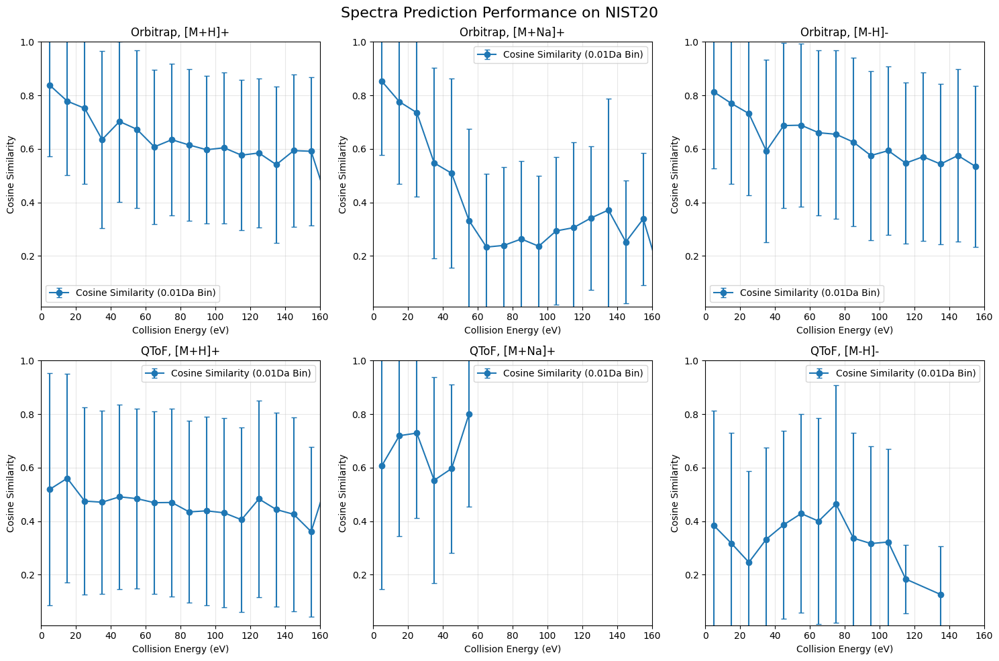

: 

In [ ]:
import matplotlib.pyplot as plt

# Create subplots for different spec_inst_type and spec_prec_type combinations
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Spectra Prediction Performance on NIST20', fontsize=16)

# Define mappings for instrument and precursor types
inst_type_labels = {0: 'Orbitrap', 1: 'QToF'}
prec_type_labels = {0: '[M+H]+', 1: '[M+Na]+', 2: '[M-H]-'}

# Get unique combinations of spec_inst_type and spec_prec_type
inst_types = grouped_stats_with_ce_df['spec_inst_type'].unique()
prec_types = grouped_stats_with_ce_df['spec_prec_type'].unique()

# Collect all y-values to determine common y-axis minimum
all_y_values = []
for inst_type in inst_types:
    for prec_type in prec_types:
        subset = grouped_stats_with_ce_df[
            (grouped_stats_with_ce_df['spec_inst_type'] == inst_type) & 
            (grouped_stats_with_ce_df['spec_prec_type'] == prec_type)
        ].dropna()
        if not subset.empty:
            all_y_values.extend(subset['cos_sim_0.01_mean'])

# Calculate y-axis range with fixed maximum at 1.0
y_min = min(all_y_values) * 0.95  # Add 5% padding below
y_max = 1.0  # Fixed maximum at 1.0

for i, inst_type in enumerate(inst_types):
    for j, prec_type in enumerate(prec_types):
        ax = axes[i, j]
        
        # Filter data for current combination
        subset = grouped_stats_with_ce_df[
            (grouped_stats_with_ce_df['spec_inst_type'] == inst_type) & 
            (grouped_stats_with_ce_df['spec_prec_type'] == prec_type)
        ].dropna()
        
        if not subset.empty:
            # Extract bin midpoints for x-axis
            bin_midpoints = [interval.mid for interval in subset['spec_ce_bin']]
            
            # Plot cosine similarity (0.01Da Bin) only
            ax.errorbar(bin_midpoints, subset['cos_sim_0.01_mean'], 
                       yerr=subset['cos_sim_0.01_std'], 
                       label='Cosine Similarity (0.01Da Bin)', marker='o', capsize=3)
        
        # Use proper labels for title
        inst_label = inst_type_labels.get(inst_type, f'Unknown_{inst_type}')
        prec_label = prec_type_labels.get(prec_type, f'Unknown_{prec_type}')
        ax.set_title(f'{inst_label}, {prec_label}')
        ax.set_xlabel('Collision Energy (eV)')
        ax.set_ylabel('Cosine Similarity')
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        # Set consistent axis limits
        ax.set_xlim(0, 160)  # Limit x-axis from 0 to 160 eV
        ax.set_ylim(y_min, y_max)  # Set consistent y-axis range with max at 1.0

plt.tight_layout()
plt.show()

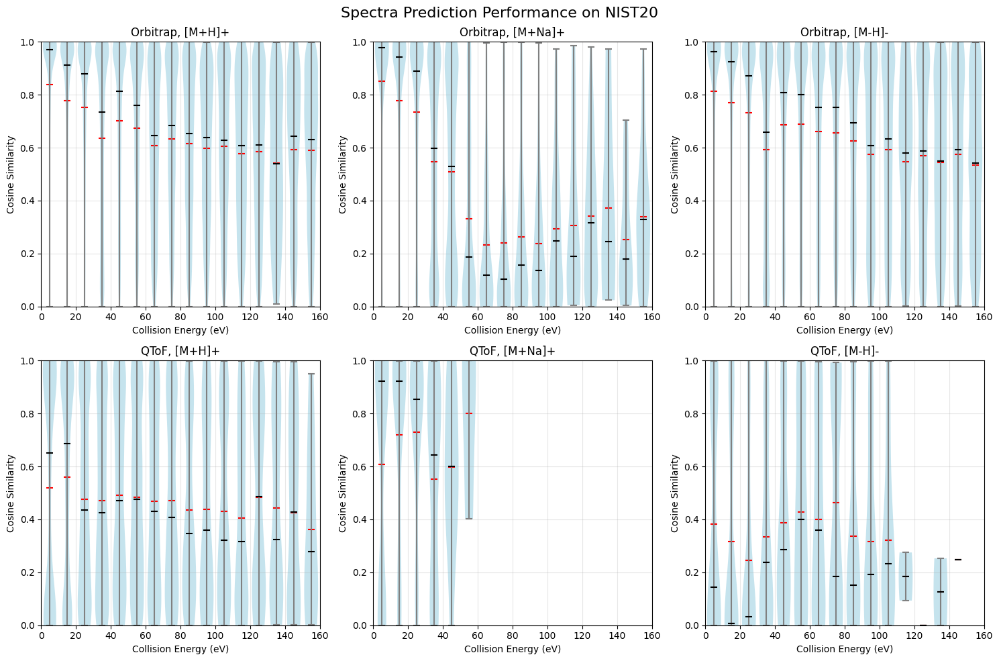

: 

In [ ]:
import matplotlib.pyplot as plt

# Create subplots for different spec_inst_type and spec_prec_type combinations
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Spectra Prediction Performance on NIST20', fontsize=16)

# Define mappings for instrument and precursor types
inst_type_labels = {0: 'Orbitrap', 1: 'QToF'}
prec_type_labels = {0: '[M+H]+', 1: '[M+Na]+', 2: '[M-H]-'}

# Get unique combinations of spec_inst_type and spec_prec_type
inst_types = grouped_stats_with_ce_df['spec_inst_type'].unique()
prec_types = grouped_stats_with_ce_df['spec_prec_type'].unique()

# Prepare data for violin plots - need to get original data grouped by collision energy bins
violin_data = []
bin_labels = []
for inst_type in inst_types:
    for prec_type in prec_types:
        # Get original data for this instrument/precursor combination
        inst_prec_data = df[
            (df['spec_inst_type'] == inst_type) & 
            (df['spec_prec_type'] == prec_type)
        ]
        
        if not inst_prec_data.empty:
            # Group by collision energy bins and collect data for violin plot
            bins = inst_prec_data['spec_ce_bin'].unique()
            bins = sorted([b for b in bins if pd.notna(b)])
            
            plot_data = []
            plot_labels = []
            for bin_interval in bins:
                bin_data = inst_prec_data[inst_prec_data['spec_ce_bin'] == bin_interval]['cos_sim_0.01']
                if len(bin_data) > 0:
                    plot_data.append(bin_data.values)
                    plot_labels.append(bin_interval.mid)
            
            violin_data.append((plot_data, plot_labels))
        else:
            violin_data.append(([], []))

# Set y-axis range
y_min = 0.0
y_max = 1.0

idx = 0
for i, inst_type in enumerate(inst_types):
    for j, prec_type in enumerate(prec_types):
        ax = axes[i, j]
        
        plot_data, plot_labels = violin_data[idx]
        idx += 1
        
        if plot_data:
            # Create violin plot
            parts = ax.violinplot(plot_data, positions=plot_labels, widths=8, showmeans=True, showmedians=True)
            
            # Customize violin plot appearance
            for pc in parts['bodies']:
                pc.set_facecolor('lightblue')
                pc.set_alpha(0.7)
            
            # Color the statistical lines
            parts['cmeans'].set_color('red')
            parts['cmedians'].set_color('black')
            parts['cbars'].set_color('gray')
            parts['cmins'].set_color('gray')
            parts['cmaxes'].set_color('gray')
        
        # Use proper labels for title
        inst_label = inst_type_labels.get(inst_type, f'Unknown_{inst_type}')
        prec_label = prec_type_labels.get(prec_type, f'Unknown_{prec_type}')
        ax.set_title(f'{inst_label}, {prec_label}')
        ax.set_xlabel('Collision Energy (eV)')
        ax.set_ylabel('Cosine Similarity')
        ax.grid(True, alpha=0.3)
        
        # Set consistent axis limits
        ax.set_xlim(0, 160)  # Limit x-axis from 0 to 160 eV
        ax.set_ylim(y_min, y_max)  # Set consistent y-axis range with max at 1.0

plt.tight_layout()
plt.show()

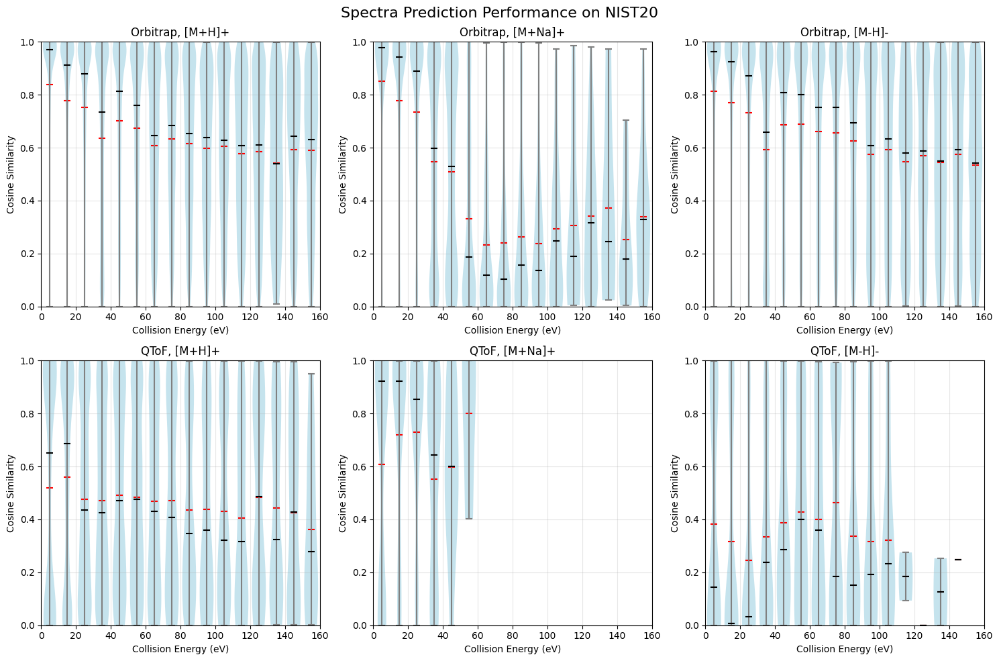

: 

In [ ]:
import matplotlib.pyplot as plt

# Create subplots for different spec_inst_type and spec_prec_type combinations
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Spectra Prediction Performance on NIST20', fontsize=16)

# Define mappings for instrument and precursor types
inst_type_labels = {0: 'Orbitrap', 1: 'QToF'}
prec_type_labels = {0: '[M+H]+', 1: '[M+Na]+', 2: '[M-H]-'}

# Get unique combinations of spec_inst_type and spec_prec_type
inst_types = grouped_stats_with_ce_df['spec_inst_type'].unique()
prec_types = grouped_stats_with_ce_df['spec_prec_type'].unique()

# Prepare data for violin plots - need to get original data grouped by collision energy bins
violin_data = []
bin_labels = []
for inst_type in inst_types:
    for prec_type in prec_types:
        # Get original data for this instrument/precursor combination
        inst_prec_data = df[
            (df['spec_inst_type'] == inst_type) & 
            (df['spec_prec_type'] == prec_type)
        ]
        
        if not inst_prec_data.empty:
            # Group by collision energy bins and collect data for violin plot
            bins = inst_prec_data['spec_ce_bin'].unique()
            bins = sorted([b for b in bins if pd.notna(b)])
            
            plot_data = []
            plot_labels = []
            for bin_interval in bins:
                bin_data = inst_prec_data[inst_prec_data['spec_ce_bin'] == bin_interval]['cos_sim_0.01']
                if len(bin_data) > 0:
                    plot_data.append(bin_data.values)
                    plot_labels.append(bin_interval.mid)
            
            violin_data.append((plot_data, plot_labels))
        else:
            violin_data.append(([], []))

# Set y-axis range
y_min = 0.0
y_max = 1.0

idx = 0
for i, inst_type in enumerate(inst_types):
    for j, prec_type in enumerate(prec_types):
        ax = axes[i, j]
        
        plot_data, plot_labels = violin_data[idx]
        idx += 1
        
        if plot_data:
            # Create violin plot
            parts = ax.violinplot(plot_data, positions=plot_labels, widths=8, showmeans=True, showmedians=True)
            
            # Customize violin plot appearance
            for pc in parts['bodies']:
                pc.set_facecolor('lightblue')
                pc.set_alpha(0.7)
            
            # Color the statistical lines
            parts['cmeans'].set_color('red')
            parts['cmedians'].set_color('black')
            parts['cbars'].set_color('gray')
            parts['cmins'].set_color('gray')
            parts['cmaxes'].set_color('gray')
        
        # Use proper labels for title
        inst_label = inst_type_labels.get(inst_type, f'Unknown_{inst_type}')
        prec_label = prec_type_labels.get(prec_type, f'Unknown_{prec_type}')
        ax.set_title(f'{inst_label}, {prec_label}')
        ax.set_xlabel('Collision Energy (eV)')
        ax.set_ylabel('Cosine Similarity')
        ax.grid(True, alpha=0.3)
        
        # Set consistent axis limits
        ax.set_xlim(0, 160)  # Limit x-axis from 0 to 160 eV
        ax.set_ylim(y_min, y_max)  # Set consistent y-axis range with max at 1.0

plt.tight_layout()
plt.show()